1.CHARGEMENT

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PATH = "../datasets/creditcard.csv"   # adapte le chemin si besoin
df = pd.read_csv(PATH)
print(df.shape)          # attendu : (284807, 31)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


2.STRUCTURE ET QUALITE


In [12]:
df.info()
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 3. Le déséquilibre des classes (le point clé du dataset)

Class
0    284315
1       492
Name: count, dtype: int64
Taux de fraude : 0.1727%
Accuracy d'un modèle idiot : 99.8273%


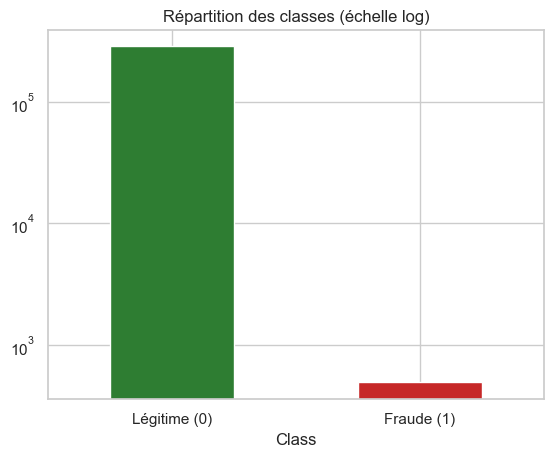

In [13]:
counts = df["Class"].value_counts()
print(counts)
print(f"Taux de fraude : {counts[1]/len(df):.4%}")

# Un modèle qui répond toujours « légitime » aurait quelle accuracy ?
print(f"Accuracy d'un modèle idiot : {counts[0]/len(df):.4%}")

counts.plot(kind="bar", logy=True, color=["#2e7d32", "#c62828"])
plt.title("Répartition des classes (échelle log)")
plt.xticks([0,1], ["Légitime (0)", "Fraude (1)"], rotation=0)
plt.show()

## 4. La colonne `Amount`

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


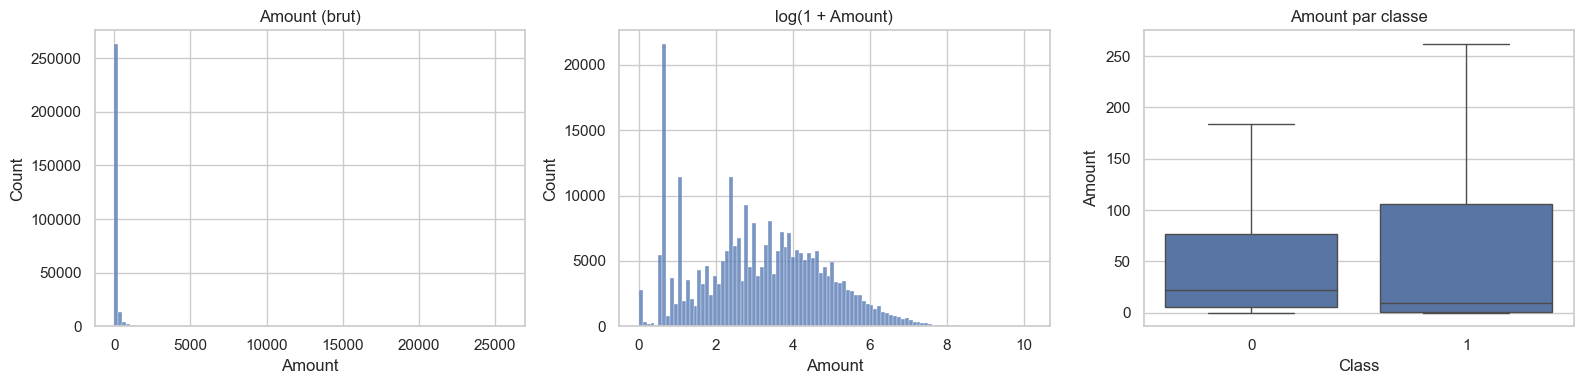

             mean  median       max
Class                              
0       88.291022   22.00  25691.16
1      122.211321    9.25   2125.87


In [14]:
print(df["Amount"].describe())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Amount"], bins=100, ax=ax[0]); ax[0].set_title("Amount (brut)")
sns.histplot(np.log1p(df["Amount"]), bins=100, ax=ax[1]); ax[1].set_title("log(1 + Amount)")
sns.boxplot(data=df, x="Class", y="Amount", ax=ax[2], showfliers=False); ax[2].set_title("Amount par classe")
plt.tight_layout(); plt.show()

print(df.groupby("Class")["Amount"].agg(["mean", "median", "max"]))

## 5. La colonne `Time`
Rappel : ce sont des **secondes depuis la 1re transaction** (0 à ~172 800 = 48 h), pas une heure de la journée.

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


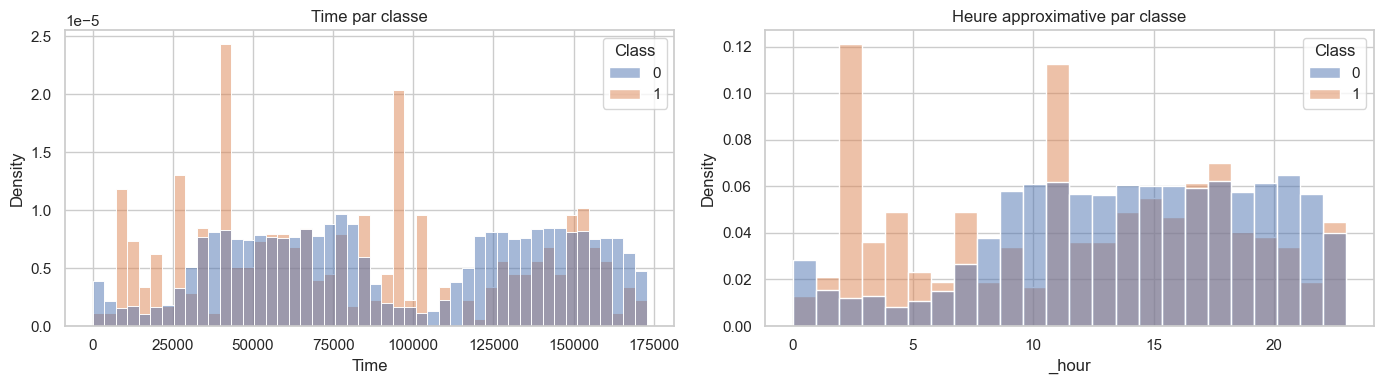

In [15]:
print(df["Time"].describe())

df["_hour"] = (df["Time"] // 3600) % 24   # colonne temporaire d'exploration
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Time", hue="Class", bins=48, stat="density", common_norm=False, ax=ax[0])
ax[0].set_title("Time par classe")
sns.histplot(data=df, x="_hour", hue="Class", bins=24, stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("Heure approximative par classe")
plt.tight_layout(); plt.show()
df = df.drop(columns="_hour")

## 6. Les variables `V1…V28` : fraude vs légitime

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
dtype: float64
V20    0.020090
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
dtype: float64


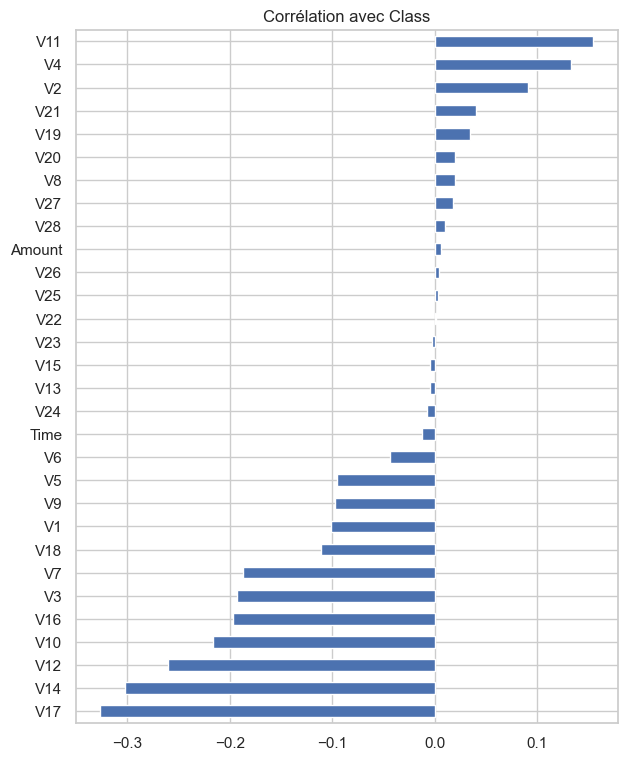

In [16]:
v_cols = [f"V{i}" for i in range(1, 29)]

# Quelles colonnes sont les plus corrélées avec la fraude ?
corr = df[v_cols + ["Amount", "Time"]].corrwith(df["Class"]).sort_values()
print(corr.head(6)); print(corr.tail(6))

corr.plot(kind="barh", figsize=(7, 9)); plt.title("Corrélation avec Class"); plt.show()

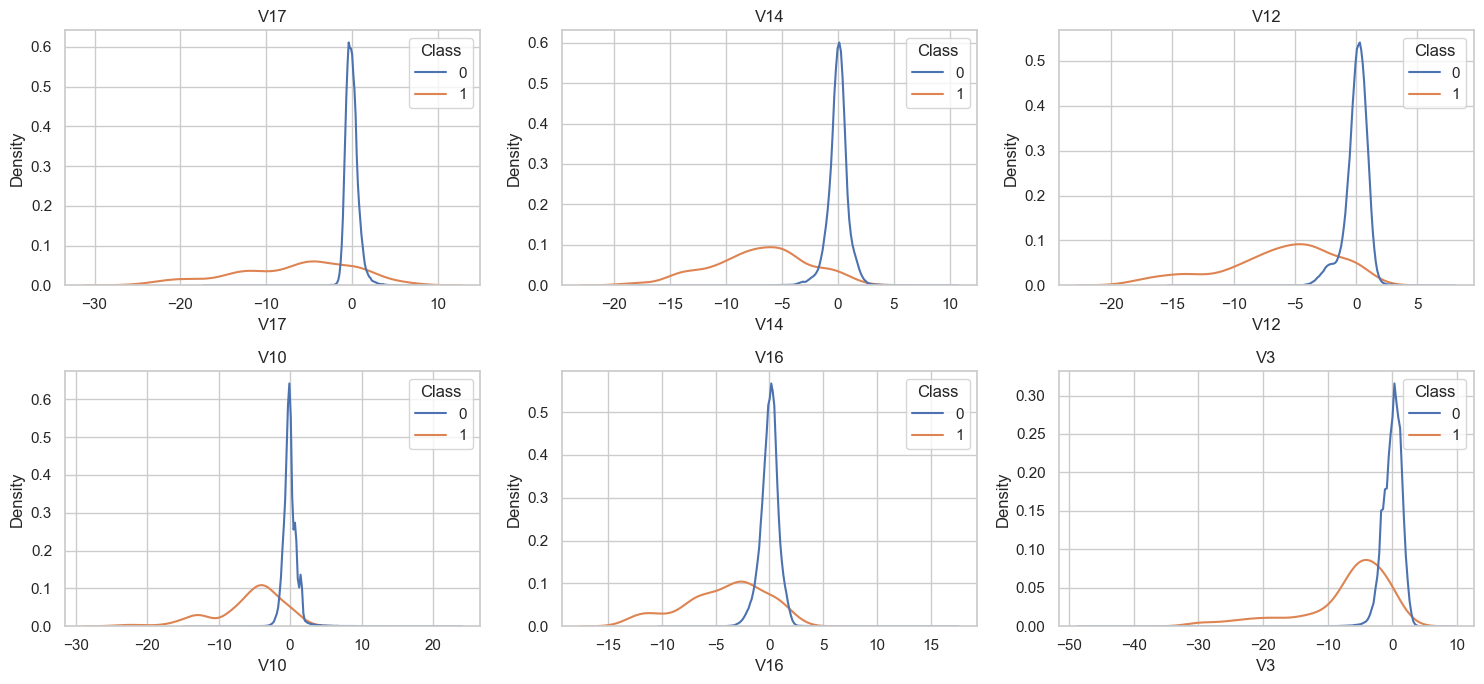

In [17]:
top = corr.abs().sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), top):
    sns.kdeplot(data=df, x=c, hue="Class", common_norm=False, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

## 7. Vérification de la cohérence (pour la suite)

In [18]:
print("Moyenne des V (attendue ~ 0) :", df[v_cols].mean().abs().max().round(3))
print("Fraudes dans un découpage 80/20 stratifié ≈", round(492*0.2), "dans le test")
df.groupby("Class")[v_cols].mean().T.head()

Moyenne des V (attendue ~ 0) : 0.0
Fraudes dans un découpage 80/20 stratifié ≈ 98 dans le test


Class,0,1
V1,0.008258,-4.771948
V2,-0.006271,3.623778
V3,0.012171,-7.033281
V4,-0.007860,4.542029
V5,0.005453,-3.151225


In [19]:
dups = df[df.duplicated(keep="first")]
print("Doublons par classe :\n", dups["Class"].value_counts())

df_unique = df.drop_duplicates()
print(df_unique.shape)
print(df_unique["Class"].value_counts())

Doublons par classe :
 Class
0    1062
1      19
Name: count, dtype: int64
(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


## 8. Conclusions de l'EDA

- **Taille** : 284 807 lignes, 31 colonnes, 0 valeur manquante.
- **Déséquilibre** : 492 fraudes soit 0,1727 % → un modèle qui répond toujours « légitime » atteint 99,83 % d'accuracy, donc l'accuracy est inutilisable ; on utilisera PR-AUC et MCC.
- **Doublons** : 1 081 lignes dupliquées (1 062 légitimes, 19 fraudes). Après suppression : 283 726 lignes, dont 283 253 légitimes et 473 fraudes (0,1667 %). À supprimer en P2.2, avant le découpage, pour éviter qu'une même ligne se retrouve dans l'entraînement et dans le test.
- **Amount** : distribution très étalée (médiane 22 €, moyenne 88 €, max 25 691 €, min 0 €) → transformation log(1 + x), car des montants à 0 existent. Les fraudes ont une médiane plus basse (9,25 €) mais une moyenne plus haute (122 €) : majorité de petits montants et quelques gros.
- **Time** : secondes sur 48 h, pas une heure de la journée ; heure de départ inconnue. Corrélation quasi nulle avec la fraude (≈ −0,01) et risque de ne pas se généraliser au-delà de ces 2 jours → à tester avec et sans en P2.2.
- **V1…V28** : anonymisées (PCA), déjà centrées autour de 0. Les plus liées à la fraude : V17, V14, V12, V10, V16, V3 (corrélations négatives), V11 et V4 (positives). Les fraudes y sont plus dispersées et décalées vers le négatif. À confirmer avec SHAP.
- **Limites** : pas de marchand/pays/IP, pas d'identifiant client, 2 jours seulement, très peu de fraudes (≈ 95 dans un test 80/20 après déduplication) → résultats variables d'un découpage à l'autre, d'où la validation croisée répétée (T3).
- **Décisions pour P2.2** :
  1. supprimer les doublons avant le découpage ;
  2. découpage stratifié entraînement / test / calibration ;
  3. log(1 + Amount) puis standardisation ;
  4. décider du sort de Time par un test avec/sans ;
  5. gérer le déséquilibre (SMOTE ou class_weight) uniquement sur l'entraînement, via un Pipeline pour éviter toute fuite de données.
